In [2]:
pip install scikit-fuzzy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 920.8/920.8 kB 14.6 MB/s eta 0:00:00


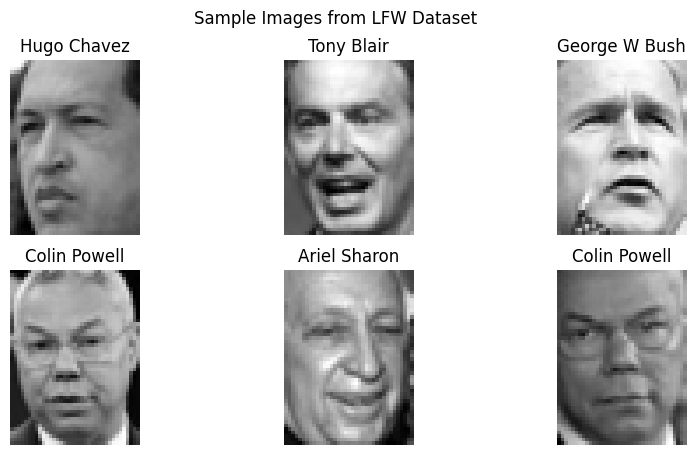

In [1]:
from sklearn.datasets import fetch_lfw_people
import matplotlib.pyplot as plt

lfw_dataset = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
lfw_images = lfw_dataset.images
lfw_labels = lfw_dataset.target
lfw_label_names = lfw_dataset.target_names

plt.figure(figsize=(10, 5))
for i in range(6):
    plt.subplot(2, 3, i + 1)
    plt.imshow(lfw_images[i], cmap="gray")
    plt.title(lfw_label_names[lfw_labels[i]])
    plt.axis("off")
plt.suptitle("Sample Images from LFW Dataset")
plt.show()

In [4]:
import numpy as np
from sklearn.datasets import fetch_lfw_people
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.preprocessing.image import img_to_array, array_to_img
import skfuzzy as fuzz
from skfuzzy.control import Antecedent, Consequent, Rule, ControlSystem, ControlSystemSimulation


lfw_dataset = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
lfw_images = lfw_dataset.images
lfw_labels = lfw_dataset.target
lfw_label_names = lfw_dataset.target_names

def preprocess_images_for_resnet(images):
    processed_images = []
    for img in images:
        img_rgb = np.stack([img] * 3, axis=-1)
        img_resized = array_to_img(img_rgb).resize((224, 224))
        img_array = img_to_array(img_resized)
        processed_images.append(preprocess_input(img_array))
    return np.array(processed_images)

lfw_images_preprocessed = preprocess_images_for_resnet(lfw_images)

X_train, X_test, y_train, y_test = train_test_split(
    lfw_images_preprocessed, lfw_labels, test_size=0.3, random_state=42
)

resnet_model = ResNet50(weights="imagenet", include_top=False, pooling="avg")

X_train_features = resnet_model.predict(X_train, batch_size=32)
X_test_features = resnet_model.predict(X_test, batch_size=32)

svm = SVC(kernel="rbf", class_weight="balanced", C=10, gamma=0.001, probability=True, random_state=42)
svm.fit(X_train_features, y_train)


confidence = Antecedent(np.arange(0, 1.1, 0.1), 'confidence')
class_overlap = Antecedent(np.arange(0, 1.1, 0.1), 'class_overlap')
prediction = Consequent(np.arange(0, 1.1, 0.1), 'prediction')

confidence['low'] = fuzz.trapmf(confidence.universe, [0, 0, 0.3, 0.5])
confidence['medium'] = fuzz.trimf(confidence.universe, [0.3, 0.5, 0.7])
confidence['high'] = fuzz.trapmf(confidence.universe, [0.5, 0.7, 1, 1])

class_overlap['low'] = fuzz.trapmf(class_overlap.universe, [0, 0, 0.3, 0.5])
class_overlap['high'] = fuzz.trapmf(class_overlap.universe, [0.5, 0.7, 1, 1])

prediction['unknown'] = fuzz.trapmf(prediction.universe, [0, 0, 0.3, 0.5])
prediction['predicted'] = fuzz.trapmf(prediction.universe, [0.5, 0.7, 1, 1])

rule1 = Rule(confidence['low'] & class_overlap['high'], prediction['unknown'])
rule2 = Rule(confidence['medium'] & class_overlap['low'], prediction['predicted'])
rule3 = Rule(confidence['high'], prediction['predicted'])

prediction_system = ControlSystem([rule1, rule2, rule3])
prediction_simulation = ControlSystemSimulation(prediction_system)

refined_predictions = []
for i in range(len(X_test_features)):
    confidence_scores = svm.predict_proba([X_test_features[i]])[0]
    max_score = max(confidence_scores)
    overlap_score = 1 - max_score

    prediction_simulation.input['confidence'] = max_score
    prediction_simulation.input['class_overlap'] = overlap_score
    prediction_simulation.compute()

    fuzzy_output = prediction_simulation.output['prediction']
    if fuzzy_output < 0.5:
        refined_predictions.append(-1)
    else:
        refined_predictions.append(svm.classes_[np.argmax(confidence_scores)])


adjusted_label_names = list(lfw_label_names) + ["Unknown"]
accuracy = accuracy_score(y_test, refined_predictions)
print("Accuracy:", accuracy)
print("Classification Report:\n", classification_report(y_test, refined_predictions, target_names=adjusted_label_names))

29/29 ━━━━━━━━━━━━━━━━━━━━ 157s 5s/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 64s 5s/step
Accuracy: 0.9250645994832042
Classification Report:
                    precision    recall  f1-score   support

     Ariel Sharon       0.00      0.00      0.00         0
     Colin Powell       1.00      0.94      0.97        18
  Donald Rumsfeld       0.96      0.99      0.97        69
    George W Bush       1.00      0.91      0.95        34
Gerhard Schroeder       0.98      0.96      0.97       166
      Hugo Chavez       0.83      0.97      0.90        31
       Tony Blair       0.85      0.58      0.69        19
          Unknown       1.00      0.82      0.90        50

         accuracy                           0.93       387
        macro avg       0.83      0.77      0.79       387
     weighted avg       0.96      0.93      0.94       387



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


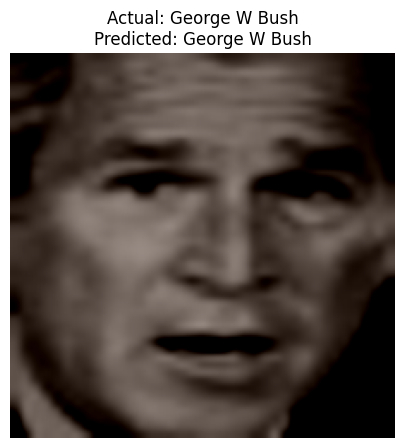

In [21]:
def display_test_image_with_prediction(index, X_test, y_test, refined_predictions, adjusted_label_names):
    """
    Display a single test image with its predicted and actual label.
    """
    test_image = X_test[index]
    test_label = y_test[index]
    predicted_label = refined_predictions[index]

    test_image = np.clip(test_image / 255.0, 0, 1)

    plt.figure(figsize=(5, 5))
    plt.imshow(test_image.squeeze(), cmap="gray")
    plt.title(
        f"Actual: {adjusted_label_names[test_label]}\n"
        f"Predicted: {adjusted_label_names[predicted_label] if predicted_label != -1 else 'Unknown'}"
    )
    plt.axis("off")
    plt.show()

import random
test_index = random.randint(0, len(X_test) - 1)
display_test_image_with_prediction(test_index, X_test, y_test, refined_predictions, adjusted_label_names)

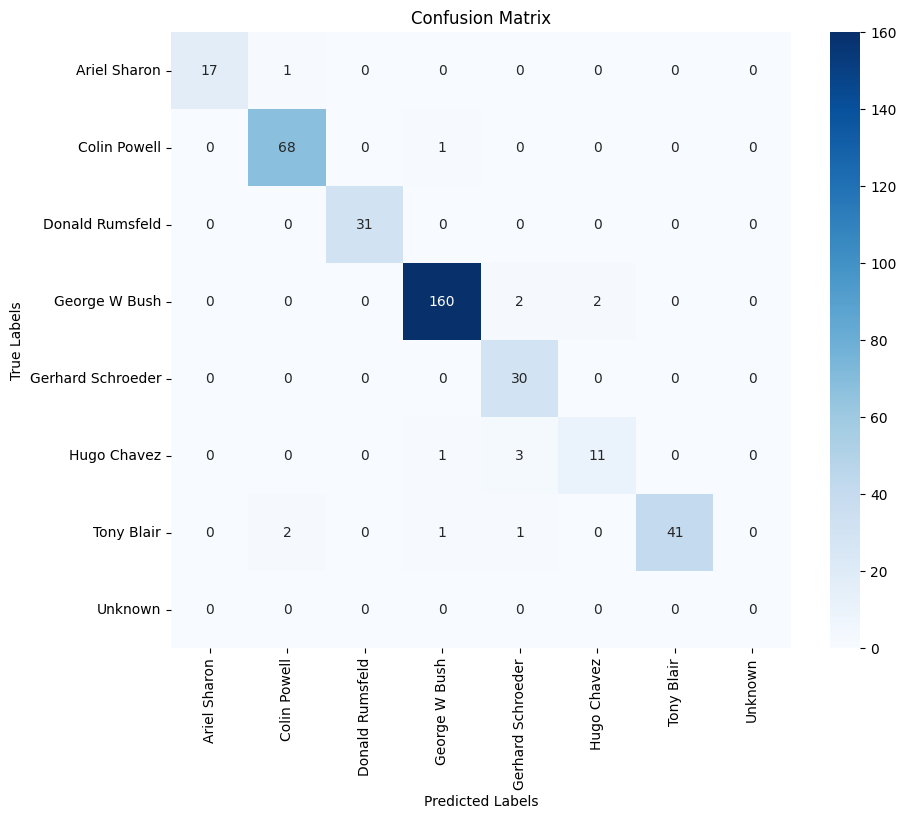

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
conf_matrix = confusion_matrix(y_test, refined_predictions, labels=range(len(adjusted_label_names)))

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=adjusted_label_names, yticklabels=adjusted_label_names)
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("Confusion Matrix")
plt.show()
